# Visualisasi Data: Histogram dan Box Plot

Histogram memperlihatkan bentuk sebaran data numerik. Box plot merangkum posisi tengah dan penyebarannya. Data berikut merupakan simulasi.

*Versi Solusi*


## Demo: durasi membaca

Setiap baris adalah durasi membaca satu siswa dalam menit.


### Menyiapkan pustaka dan data


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

data_baca = pd.DataFrame({
    'Siswa': [f'S{i:02d}' for i in range(1, 21)],
    'Durasi_Menit': [12, 15, 18, 19, 21, 22, 23, 24, 25, 26,
                     27, 28, 29, 31, 32, 34, 35, 38, 42, 48],
})
data_baca


## Histogram: frekuensi dalam interval

Histogram mengelompokkan nilai numerik ke dalam interval atau *bin*. Tinggi batang menunjukkan banyaknya pengamatan pada interval itu.


### Membuat histogram durasi membaca

Batas bin berikut berjarak 10 menit. Interval mencakup batas kiri dan tidak mencakup batas kanan, kecuali bin terakhir yang mencakup kedua batas.


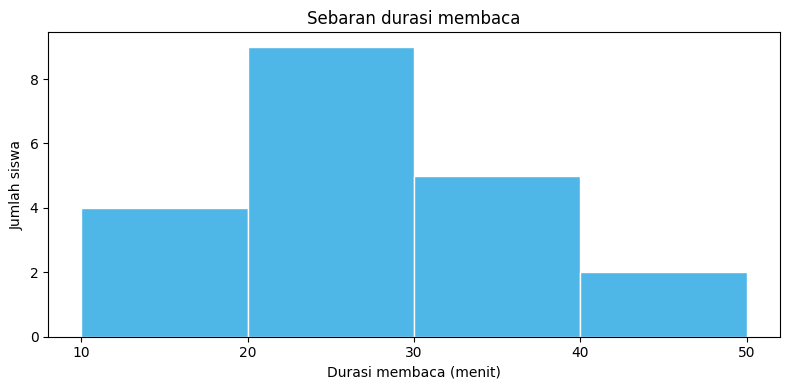

In [6]:
batas_baca = [10, 20, 30, 40, 50]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(data_baca['Durasi_Menit'], bins=batas_baca, edgecolor='white', color='#4FB6E8')
ax.set_title('Sebaran durasi membaca')
ax.set_xlabel('Durasi membaca (menit)')
ax.set_ylabel('Jumlah siswa')
ax.set_xticks(batas_baca)
plt.tight_layout()
plt.show()


Pada contoh ini, interval 20 sampai kurang dari 30 menit paling sering muncul. Batang yang berdampingan menunjukkan interval numerik yang berurutan.


### Pengaruh pilihan bin

Batas yang lebih lebar menggabungkan lebih banyak nilai dalam satu batang. Bandingkan bentuknya sebelum menyimpulkan pola.


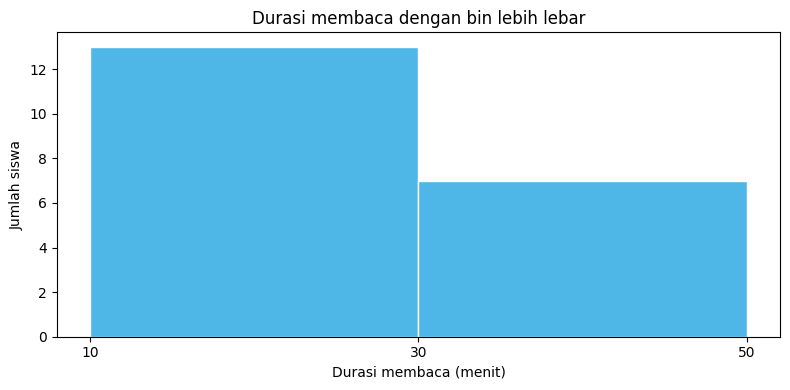

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(data_baca['Durasi_Menit'], bins=[10, 30, 50], edgecolor='white', color='#4FB6E8')
ax.set_title('Durasi membaca dengan bin lebih lebar')
ax.set_xlabel('Durasi membaca (menit)')
ax.set_ylabel('Jumlah siswa')
ax.set_xticks([10, 30, 50])
plt.tight_layout()
plt.show()


## Practice Tengah: nilai kuis

Data simulasi berikut berisi nilai kuis dari 24 siswa. Setiap baris mewakili satu siswa.

### Data nilai kuis

In [12]:
data_kuis = pd.DataFrame({
    'Siswa': [f'S{i:02d}' for i in range(1, 25)],
    'Nilai': [58, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 73,
              52, 55, 58, 60, 62, 64, 66, 68, 70, 73, 76, 98],
})
data_kuis

### Tugas histogram

1. Buat histogram seluruh nilai dengan batas bin `[50, 60, 70, 80, 90, 100]`.
2. Beri judul, label sumbu dan tanda batas bin.
3. Tampilkan jumlah siswa dan jelaskan interval yang paling sering muncul.

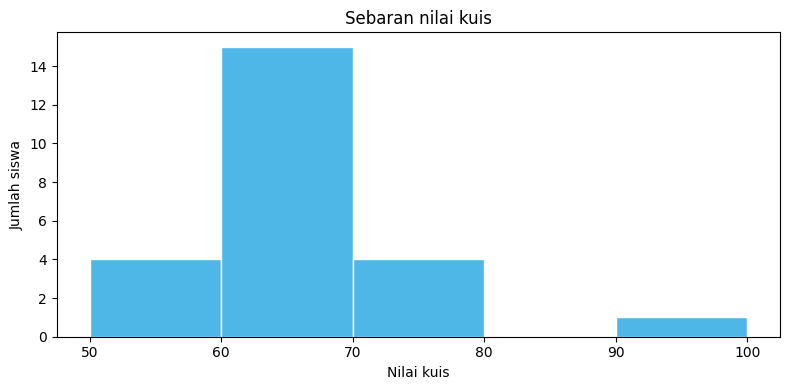

Jumlah siswa: 24
Interval 60 sampai kurang dari 70 paling sering muncul.


In [14]:
batas_nilai = [50, 60, 70, 80, 90, 100]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(data_kuis['Nilai'], bins=batas_nilai, edgecolor='white', color='#4FB6E8')
ax.set_title('Sebaran nilai kuis')
ax.set_xlabel('Nilai kuis')
ax.set_ylabel('Jumlah siswa')
ax.set_xticks(batas_nilai)
plt.tight_layout()
plt.show()
print('Jumlah siswa:', len(data_kuis))
print('Interval 60 sampai kurang dari 70 paling sering muncul.')

## Box plot: posisi tengah dan penyebaran

Garis di dalam kotak adalah median. Kotak membentang dari kuartil pertama (Q1) sampai kuartil ketiga (Q3), sehingga berisi sekitar 50% data tengah.


### Ringkasan kuartil dan IQR

IQR adalah Q3 dikurangi Q1. Nilai Q1 dan Q3 pada contoh dihitung dengan metode interpolasi default pandas.


In [17]:
durasi_baca = data_baca['Durasi_Menit']
q1 = durasi_baca.quantile(0.25)
median = durasi_baca.median()
q3 = durasi_baca.quantile(0.75)
iqr = q3 - q1
print(f'Q1: {q1:.2f} menit')
print(f'Median: {median:.2f} menit')
print(f'Q3: {q3:.2f} menit')
print(f'IQR: {iqr:.2f} menit')


Q1: 21.75 menit
Median: 26.50 menit
Q3: 32.50 menit
IQR: 10.75 menit


### Membaca whisker dan pencilan

Dengan aturan default Matplotlib, whisker mencapai pengamatan terjauh yang masih berada dalam batas Q1 − 1,5 × IQR dan Q3 + 1,5 × IQR. Titik di luar batas ditandai sebagai pencilan potensial, bukan otomatis data salah.


In [19]:
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
pencilan = durasi_baca[(durasi_baca < batas_bawah) | (durasi_baca > batas_atas)]
print(f'Batas pencilan: {batas_bawah:.2f} sampai {batas_atas:.2f} menit')
print('Pencilan potensial:', pencilan.tolist())


Batas pencilan: 5.62 sampai 48.62 menit
Pencilan potensial: []


### Membuat box plot

Bandingkan median dan panjang kotak dengan tabel kuartil di atas. Batas pencilan tidak selalu sama dengan ujung whisker.


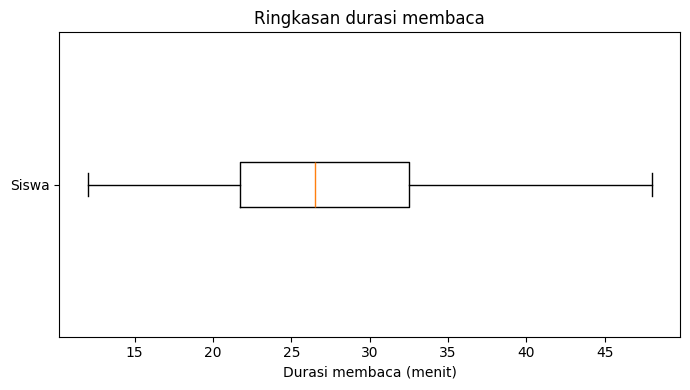

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(durasi_baca, vert=False)
ax.set_title('Ringkasan durasi membaca')
ax.set_xlabel('Durasi membaca (menit)')
ax.set_yticks([1])
ax.set_yticklabels(['Siswa'])
plt.tight_layout()
plt.show()


## Practice Akhir: paket yang diproses

Data simulasi berikut berisi jumlah paket yang diproses setiap petugas dalam satu hari. Bandingkan kelompok A dan B menggunakan satu box plot.

### Data jumlah paket

In [24]:
data_paket = pd.DataFrame({
    'Petugas': [f'P{i:02d}' for i in range(1, 25)],
    'Kelompok': ['A'] * 12 + ['B'] * 12,
    'Jumlah_Paket': [18, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 33,
                     12, 15, 18, 20, 22, 24, 26, 28, 30, 33, 36, 58],
})
data_paket

### Tugas box plot dan interpretasi

1. Pisahkan jumlah paket kelompok A dan B. Buat satu box plot kedua kelompok dengan label dan satuan yang jelas.
2. Tampilkan median, Q1, Q3 dan IQR tiap kelompok. Tentukan pencilan potensial menggunakan aturan 1,5 × IQR.
3. Bandingkan posisi tengah, penyebaran 50% data tengah, dan pencilan potensial kedua kelompok.

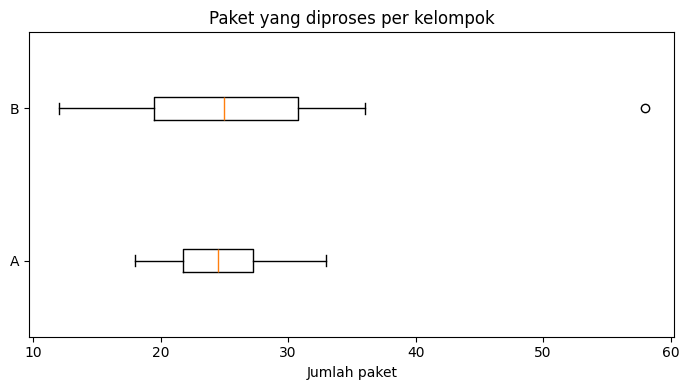

A: Q1=21.75, median=24.50, Q3=27.25, IQR=5.50 paket
  Pencilan potensial: []
B: Q1=19.50, median=25.00, Q3=30.75, IQR=11.25 paket
  Pencilan potensial: [58]
Median kelompok A adalah 24,5 paket dan kelompok B adalah 25 paket.
IQR kelompok B lebih besar, sehingga 50% data tengahnya lebih menyebar.
Kelompok B memiliki pencilan potensial 58 paket, A tidak memiliki pencilan potensial.


In [26]:
a = data_paket.loc[data_paket['Kelompok'] == 'A', 'Jumlah_Paket']
b = data_paket.loc[data_paket['Kelompok'] == 'B', 'Jumlah_Paket']

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([a, b], vert=False)
ax.set_yticks([1, 2])
ax.set_yticklabels(['A', 'B'])
ax.set_xlabel('Jumlah paket')
ax.set_title('Paket yang diproses per kelompok')
plt.tight_layout()
plt.show()

for nama, nilai in [('A', a), ('B', b)]:
    q1 = nilai.quantile(0.25)
    median = nilai.median()
    q3 = nilai.quantile(0.75)
    iqr = q3 - q1
    pencilan = nilai[(nilai < q1 - 1.5 * iqr) | (nilai > q3 + 1.5 * iqr)]
    print(f'{nama}: Q1={q1:.2f}, median={median:.2f}, Q3={q3:.2f}, IQR={iqr:.2f} paket')
    print('  Pencilan potensial:', pencilan.tolist())

print('Median kelompok A adalah 24,5 paket dan kelompok B adalah 25 paket.')
print('IQR kelompok B lebih besar, sehingga 50% data tengahnya lebih menyebar.')
print('Kelompok B memiliki pencilan potensial 58 paket, A tidak memiliki pencilan potensial.')

## Memilih grafik

- Histogram menunjukkan frekuensi dan bentuk sebaran, tetapi tampilan dipengaruhi pilihan bin.
- Box plot merangkum median, kuartil dan pencilan potensial, tetapi tidak memperlihatkan frekuensi tiap interval.


## Referensi API

- [Matplotlib histogram](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html)
- [Matplotlib box plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.boxplot.html)
- [Pandas quantile](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html)
